# CELL 1 — SenseFi (UT-HAR, supervised) — Reproducibility Notebook

**Target paper:** *SenseFi: A Library and Benchmark on Deep-Learning-Empowered WiFi Human Sensing* (Yang et al., Patterns 2023; arXiv 2207.07859v3).
**Experiment reproduced (REQUIRED):** Table III, **UT-HAR** column — supervised learning, 11 baseline models, accuracy.
**Source of truth for code:** the authors' repository files (`dataset.py`, `util.py`, `run.py`, `UT_HAR_model.py`).

Provenance labels used throughout:
- **[Reproduced]** follows paper and/or repository exactly
- **[Adapted]** changed only for Kaggle / to allow a leak-free checkpoint choice
- **[New]** not in the paper or repository (extra metrics, seeds, diagnostics)

> This notebook re-runs the paper's methodology through the authors' code. It does **not** claim an exact reproduction of the paper's numbers.

# CELL 2 — Install dependencies
`einops` is imported by the repo model files (not preinstalled on Kaggle). `thop` is optional (FLOPs/MACs check only).

In [1]:
import subprocess, sys

def pip_install(pkg):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg],
                       capture_output=True, text=True)
    print(f"pip install {pkg}: {'OK' if r.returncode == 0 else 'FAILED'}")
    if r.returncode != 0:
        print(r.stderr[-400:])
    return r.returncode == 0

pip_install("einops")          # required by repo model files (rearrange / Reduce / repeat)
HAVE_THOP = pip_install("thop")  # optional: MACs counter; the notebook runs without it

pip install einops: OK
pip install thop: OK


# CELL 3 — Imports

In [2]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # must be set before CUDA init (determinism)

import copy, glob, json, platform, random, time
from pathlib import Path

import numpy as np                      # array loading / normalisation (repo dataset.py uses np.load)
import pandas as pd                     # history + result tables
import matplotlib.pyplot as plt         # curves and confusion matrices
from IPython.display import display     # table rendering in notebook cells

import torch                            # framework used by the repo
import torch.nn as nn
import torch.nn.functional as F         # used by repo ViT attention (softmax)
from torch.utils.data import TensorDataset, DataLoader

from einops import rearrange, repeat    # repo ViT
from einops.layers.torch import Rearrange, Reduce

import sklearn
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

print("python", platform.python_version(), "| torch", torch.__version__,
      "| numpy", np.__version__, "| sklearn", sklearn.__version__)

python 3.12.13 | torch 2.10.0+cu128 | numpy 2.0.2 | sklearn 1.6.1


# CELL 4 — Reproducibility configuration

Every value is tagged with its source.

| Setting | Value | Source |
|---|---|---|
| Optimizer / LR / betas | Adam, 1e-3, (0.9, 0.999) | **Paper** Sec. V-B; **repo** `run.py` (`Adam(lr=1e-3)`, default betas) |
| Epochs (UT-HAR) | 200 | **Paper** Table II/V-B; **repo** `util.py` |
| Epochs (RNN) | paper: 2x = **400**; repo `util.py`: **3000** | **CONFLICT** — see `rnn_epoch_source` |
| Train batch / test batch | 64 (shuffle, drop_last) / 256 | **Repo** `util.py` — the paper does not specify batch size |
| LR scheduler / early stopping | none | **Repo** (none present); paper does not mention any |
| Loss | CrossEntropyLoss | **Repo** `run.py` — the paper does not specify |
| Seed | 42 | **[New]** — the repo sets no seed |
| Mixed precision | off | **[Adapted]** disabled to stay faithful/deterministic |

In [3]:
DEBUG_MODE = False   # True -> 2 epochs, outputs go to /debug (NOT the paper configuration)

CONFIG = {
    "dataset": "UT_HAR_data",
    "models": ["LeNet"],                 # any of: MLP LeNet ResNet18 ResNet50 ResNet101 RNN GRU LSTM BiLSTM CNN+GRU ViT
    "seed": 42,                          # [New]
    "train_batch_size": 64,              # repo util.py
    "test_batch_size": 256,              # repo util.py
    "lr": 1e-3,                          # paper + repo
    "betas": (0.9, 0.999),               # paper + repo (Adam default)
    "epochs": 200,                       # paper + repo for UT-HAR
    "rnn_epoch_source": "paper",         # "paper" -> 400 (2x200)   |   "repo" -> 3000   (source conflict)
    "norm_mode": "repo_per_file",        # "repo_per_file" (repo dataset.py)  |  "train_stats" (leak-free alternative)
    "num_workers": 0,
    "ckpt_every": 10,                    # how often last_model.pth/history are flushed to disk
    "data_dir_override": None,           # set a path only if auto-discovery fails
}
ALL_MODELS = ["MLP","LeNet","ResNet18","ResNet50","ResNet101","RNN","GRU","LSTM","BiLSTM","CNN+GRU","ViT"]
assert all(m in ALL_MODELS for m in CONFIG["models"]), "unknown model name in CONFIG['models']"

def epochs_for(model_name):
    if DEBUG_MODE:
        return 2
    if model_name == "RNN":
        return 400 if CONFIG["rnn_epoch_source"] == "paper" else 3000
    return CONFIG["epochs"]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

set_seed(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only (training will be slow)")

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./working")
OUT_DIR = WORK / ("debug" if DEBUG_MODE else "paper_config")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("output dir:", OUT_DIR, "| DEBUG_MODE =", DEBUG_MODE)

device: cuda | Tesla T4
output dir: /kaggle/working/paper_config | DEBUG_MODE = False


# CELL 5 — Kaggle dataset path configuration
The repo expects `Data/UT_HAR/data/{X_train,X_val,X_test}.csv` and `Data/UT_HAR/label/{y_train,y_val,y_test}.csv`
(files are **NumPy binaries with a .csv extension**, loaded with `np.load`). Here the files are located wherever the Kaggle dataset puts them.

In [4]:
REQUIRED = ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test"]

def find_files(stem):
    roots = [CONFIG["data_dir_override"]] if CONFIG["data_dir_override"] else ["/kaggle/input", "./Data"]
    hits = []
    for r in roots:
        if r and os.path.exists(r):
            hits += glob.glob(os.path.join(r, "**", f"{stem}.csv"), recursive=True)
    return sorted(set(hits))

PATHS = {}
for stem in REQUIRED:
    hits = find_files(stem)
    if not hits:
        raise FileNotFoundError(
            f"Missing {stem}.csv under /kaggle/input or ./Data. Add the UT-HAR processed dataset "
            f"(Data/UT_HAR/data + label) to this notebook, or set CONFIG['data_dir_override'].")
    if len(hits) > 1:
        print(f"WARNING: {stem}.csv found {len(hits)} times; using the first:\n   " + "\n   ".join(hits))
    PATHS[stem] = hits[0]

for k, v in PATHS.items():
    print(f"{k:8s} -> {v}  ({os.path.getsize(v)/1e6:.1f} MB)")

X_train  -> /kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/data/X_train.csv  (715.9 MB)
X_val    -> /kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/data/X_val.csv  (89.3 MB)
X_test   -> /kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/data/X_test.csv  (90.0 MB)
y_train  -> /kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/label/y_train.csv  (0.0 MB)
y_val    -> /kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/label/y_val.csv  (0.0 MB)
y_test   -> /kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/label/y_test.csv  (0.0 MB)


# CELL 6 — Dataset/file verification
Checks each file really is a NumPy array before anything else is built on it.

In [5]:
def load_npy_like(path):
    # repo dataset.py: `with open(path,'rb') as f: np.load(f)` (CSV extension, NumPy content)
    try:
        with open(path, "rb") as f:
            return np.load(f, allow_pickle=False)
    except Exception as e:
        raise RuntimeError(f"{path} is not a NumPy binary ({e}). The README warns the UT-HAR files are not "
                           f"real CSVs; re-download the processed data and do not open/re-save it in Excel.")

RAW = {k: load_npy_like(p) for k, p in PATHS.items()}
for k, a in RAW.items():
    print(f"{k:8s} shape={a.shape} dtype={a.dtype}")

X_train  shape=(3977, 250, 90) dtype=float64
X_val    shape=(496, 250, 90) dtype=float64
X_test   shape=(500, 250, 90) dtype=float64
y_train  shape=(3977,) dtype=int64
y_val    shape=(496,) dtype=int64
y_test   shape=(500,) dtype=int64


# CELL 7 — Dataset loading (repo `UT_HAR_dataset`)
Repo does `data.reshape(len(data),1,250,90)`. The reshape is **verified**, not assumed.

In [6]:
X_RAW, Y_RAW = {}, {}
for split in ["train", "val", "test"]:
    x = RAW[f"X_{split}"]
    n = len(x)
    assert x.size == n * 250 * 90, (f"X_{split}: {x.shape} cannot be reshaped to (N,1,250,90) "
                                    f"(size {x.size} != {n*250*90}). Dataset layout differs from the repo.")
    X_RAW[split] = x.reshape(n, 1, 250, 90)
    y = np.asarray(RAW[f"y_{split}"]).reshape(-1)
    assert len(y) == n, f"y_{split} has {len(y)} labels but X_{split} has {n} samples"
    assert np.all(y == np.round(y)), f"y_{split} contains non-integer labels"
    Y_RAW[split] = y.astype(np.int64)
    print(f"{split:5s}: X {X_RAW[split].shape}   y {Y_RAW[split].shape}")

train: X (3977, 1, 250, 90)   y (3977,)
val  : X (496, 1, 250, 90)   y (496,)
test : X (500, 1, 250, 90)   y (500,)


# CELL 8 — Dataset statistics, integrity checks, paper comparison

In [7]:
# README order of classes; the index<->name mapping is NOT stated in repo code (assumption used only for plot labels)
CLASS_NAMES = ["lie down", "fall", "walk", "pickup", "run", "sit down", "stand up"]
PAPER_STATS = {"classes": 7, "train": 3977, "test": 996, "repo_input": (1, 250, 90), "paper_input": "(3,30,250)"}

print("Dataset path root:", os.path.commonpath([os.path.dirname(p) for p in PATHS.values()]))
all_y = np.concatenate([Y_RAW[s] for s in ["train", "val", "test"]])
n_classes = int(all_y.max()) + 1
assert all_y.min() == 0 and len(np.unique(all_y)) == n_classes, "labels are not contiguous 0..K-1"
print("Number of classes:", n_classes, "| unexpected labels:", int(((all_y < 0) | (all_y >= 7)).sum()))

rows = []
for s in ["train", "val", "test"]:
    x = X_RAW[s]
    rows.append({"split": s, "samples": len(x),
                 "NaN": int(np.isnan(x).sum()), "Inf": int(np.isinf(x).sum()),
                 "min": float(x.min()), "max": float(x.max()),
                 "constant_samples": int((x.reshape(len(x), -1).std(1) == 0).sum()),
                 **{f"c{c}": int((Y_RAW[s] == c).sum()) for c in range(n_classes)}})
stats = pd.DataFrame(rows).set_index("split")
display(stats)

n_train = len(X_RAW["train"]); n_val = len(X_RAW["val"]); n_testonly = len(X_RAW["test"]); n_repo_test = n_val + n_testonly
print(f"\nInput shape per sample (repo): {X_RAW['train'].shape[1:]}")
print("\nPAPER (Table II)           :", f"classes={PAPER_STATS['classes']}, train={PAPER_STATS['train']}, test={PAPER_STATS['test']}, size={PAPER_STATS['paper_input']} (antenna,subcarrier,packet)")
print("IMPLEMENTATION (repo files):", f"classes={n_classes}, train={n_train}, test(val+test)={n_repo_test}  [val={n_val}, test-only={n_testonly}]")
ok = (n_classes == PAPER_STATS["classes"], n_train == PAPER_STATS["train"], n_repo_test == PAPER_STATS["test"])
print("STATUS:", "MATCH" if all(ok) else f"MISMATCH (classes/train/test match flags = {ok}) -> investigate dataset version")
print("NOTE: paper lists (3,30,250); repo reshapes to (1,250,90) = 3 antennas x 30 subcarriers flattened to 90.")
assert stats[["NaN", "Inf"]].to_numpy().sum() == 0, "NaN/Inf present in raw CSI"

# [New] split-overlap diagnostic: UT-HAR is cut with a sliding window (paper Sec. V-A), so frames can recur across splits.
def frame_hashes(x):
    x = np.ascontiguousarray(x.reshape(len(x), 250, 90))
    return {hash(fr.tobytes()) for sample in x for fr in sample}
tr_h = frame_hashes(X_RAW["train"])
for s in ["val", "test"]:
    h = frame_hashes(X_RAW[s])
    print(f"[New] fraction of distinct {s} frames that also occur in train: {len(h & tr_h)/len(h):.3f}")
print("Interpretation: values well above 0 mean temporally overlapping windows are split across train/eval "
      "(no recording/subject IDs exist in the files, so a subject/session split is impossible here).")

Dataset path root: /kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR
Number of classes: 7 | unexpected labels: 0


,samples,NaN,Inf,min,max,constant_samples,c0,c1,c2,c3,c4,c5,c6
split,,,,,,,,,,,,,
train,3977,0,0,-10.6660,30.5190,0,525,354,1172,396,967,320,243
val,496,0,0,-9.9564,30.5395,0,66,44,146,49,121,40,30
test,500,0,0,-9.9005,30.5395,0,66,45,147,50,121,40,31



Input shape per sample (repo): (1, 250, 90)

PAPER (Table II)           : classes=7, train=3977, test=996, size=(3,30,250) (antenna,subcarrier,packet)
IMPLEMENTATION (repo files): classes=7, train=3977, test(val+test)=996  [val=496, test-only=500]
STATUS: MATCH
NOTE: paper lists (3,30,250); repo reshapes to (1,250,90) = 3 antennas x 30 subcarriers flattened to 90.
[New] fraction of distinct val frames that also occur in train: 0.820
[New] fraction of distinct test frames that also occur in train: 0.821
Interpretation: values well above 0 mean temporally overlapping windows are split across train/eval (no recording/subject IDs exist in the files, so a subject/session split is impossible here).


# CELL 9 — Preprocessing (normalisation)
**Repo (`dataset.py`)**: each file is min-max normalised with *its own* min/max (`X_train`, `X_val`, `X_test` separately).
The paper only says "we normalize the data for each dataset" — the method is **not specified**.
`norm_mode="repo_per_file"` is the faithful default; `"train_stats"` fits min/max on train only and applies it to val/test (leak-free **[Adapted]** variant).

In [8]:
def minmax(a, lo, hi):
    return (a - lo) / (hi - lo)

X_NORM = {}
if CONFIG["norm_mode"] == "repo_per_file":
    for s in ["train", "val", "test"]:
        a = X_RAW[s]; X_NORM[s] = minmax(a, a.min(), a.max())
elif CONFIG["norm_mode"] == "train_stats":
    lo, hi = X_RAW["train"].min(), X_RAW["train"].max()
    for s in ["train", "val", "test"]:
        X_NORM[s] = minmax(X_RAW[s], lo, hi)
else:
    raise ValueError("norm_mode must be 'repo_per_file' or 'train_stats'")

T = {s: torch.tensor(np.asarray(X_NORM[s]), dtype=torch.float32) for s in X_NORM}
Y = {s: torch.tensor(Y_RAW[s], dtype=torch.long) for s in Y_RAW}
for s in T:
    print(f"{s:5s} X {tuple(T[s].shape)} {T[s].dtype} range [{T[s].min():.3f}, {T[s].max():.3f}] | y {tuple(Y[s].shape)} {Y[s].dtype}")
print("norm_mode:", CONFIG["norm_mode"], "(repo-faithful)" if CONFIG["norm_mode"] == "repo_per_file" else "(adapted, leak-free)")

train X (3977, 1, 250, 90) torch.float32 range [0.000, 1.000] | y (3977,) torch.int64
val   X (496, 1, 250, 90) torch.float32 range [0.000, 1.000] | y (496,) torch.int64
test  X (500, 1, 250, 90) torch.float32 range [0.000, 1.000] | y (500,) torch.int64
norm_mode: repo_per_file (repo-faithful)


# CELL 10 — Train / validation / test split
**Repo (`util.py`)**: train = `X_train` (3977); "test" = `cat(X_val, X_test)` (996). No separate validation set is used.
**Paper** states an 8:2 stratified split; for UT-HAR the data ships pre-split (the code does not stratify) — the sizes agree with 8:2 but stratification cannot be verified.

**[Adapted]** To permit leak-free checkpoint selection, the 996 repo-test samples stay separable as `val` (496) and `test-only` (500).
Three reporting protocols are produced later:
1. **Repo protocol** — final-epoch weights, all 996 samples (what the repo prints; comparable to the paper)
2. **Clean protocol** — best-*val* checkpoint, evaluated on the 500 `test-only` samples
3. **Oracle best-epoch on 996** — informational only (selects on test; *not* valid as a result)

In [9]:
train_set = TensorDataset(T["train"], Y["train"])
val_set   = TensorDataset(T["val"],   Y["val"])
test_set  = TensorDataset(T["test"],  Y["test"])
print(f"train={len(train_set)}  val={len(val_set)}  test-only={len(test_set)}  repo-test(val+test)={len(val_set)+len(test_set)}")

train=3977  val=496  test-only=500  repo-test(val+test)=996


# CELL 11 — DataLoaders
Repo: train batch 64, `shuffle=True`, `drop_last=True`; test batch 256, no shuffle. Train shuffling is seeded **[New]**.

In [10]:
def make_train_loader(seed):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(train_set, batch_size=CONFIG["train_batch_size"], shuffle=True, drop_last=True,
                      generator=g, num_workers=CONFIG["num_workers"], pin_memory=(DEVICE.type == "cuda"))

val_loader  = DataLoader(val_set,  batch_size=CONFIG["test_batch_size"], shuffle=False, num_workers=CONFIG["num_workers"])
test_loader = DataLoader(test_set, batch_size=CONFIG["test_batch_size"], shuffle=False, num_workers=CONFIG["num_workers"])

xb, yb = next(iter(make_train_loader(CONFIG["seed"])))
print("train batch:", tuple(xb.shape), xb.dtype, "| labels:", tuple(yb.shape), yb.dtype, "| train batches/epoch:", len(make_train_loader(0)))

train batch: (64, 1, 250, 90) torch.float32 | labels: (64,) torch.int64 | train batches/epoch: 62


# CELL 12 — Model definitions (verbatim from `UT_HAR_model.py`)
No layer, dimension or quirk has been altered. Repo quirks kept on purpose:
- ViT attention applies the `1/sqrt(emb_size)` scaling **after** the softmax (non-standard).
- `CNN+GRU` ends in `nn.Softmax` and is then trained with `CrossEntropyLoss` (softmax applied twice).
- `UT_HAR_BiLSTM` classifies from `ht[-1]` (the *backward* direction's final state), hidden size 64 → `fc(64→7)`.

In [11]:
class UT_HAR_MLP(nn.Module):
    def __init__(self):
        super(UT_HAR_MLP,self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(250*90,1024),
            nn.ReLU(),
            nn.Linear(1024,128),
            nn.ReLU(),
            nn.Linear(128,7)
        )
    def forward(self,x):
        x = x.view(-1,250*90)
        x = self.fc(x)
        return x


class UT_HAR_LeNet(nn.Module):   # paper name: CNN-5
    def __init__(self):
        super(UT_HAR_LeNet,self).__init__()
        self.encoder = nn.Sequential(
            #input size: (1,250,90)
            nn.Conv2d(1,32,7,stride=(3,1)),
            nn.ReLU(True),
            nn.MaxPool2d(2),
            nn.Conv2d(32,64,(5,4),stride=(2,2),padding=(1,0)),
            nn.ReLU(True),
            nn.MaxPool2d(2),
            nn.Conv2d(64,96,(3,3),stride=1),
            nn.ReLU(True),
            nn.MaxPool2d(2)
        )
        self.fc = nn.Sequential(
            nn.Linear(96*4*4,128),
            nn.ReLU(),
            nn.Linear(128,7)
        )
    def forward(self,x):
        x = self.encoder(x)
        x = x.view(-1,96*4*4)
        out = self.fc(x)
        return out


class Bottleneck(nn.Module):
    expansion = 4
    def __init__(self, in_channels, out_channels, i_downsample=None, stride=1):
        super(Bottleneck, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, padding=0)
        self.batch_norm1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=stride, padding=1)
        self.batch_norm2 = nn.BatchNorm2d(out_channels)
        self.conv3 = nn.Conv2d(out_channels, out_channels*self.expansion, kernel_size=1, stride=1, padding=0)
        self.batch_norm3 = nn.BatchNorm2d(out_channels*self.expansion)
        self.i_downsample = i_downsample
        self.stride = stride
        self.relu = nn.ReLU()
    def forward(self, x):
        identity = x.clone()
        x = self.relu(self.batch_norm1(self.conv1(x)))
        x = self.relu(self.batch_norm2(self.conv2(x)))
        x = self.conv3(x)
        x = self.batch_norm3(x)
        if self.i_downsample is not None:
            identity = self.i_downsample(identity)
        x+=identity
        x=self.relu(x)
        return x

class Block(nn.Module):
    expansion = 1
    def __init__(self, in_channels, out_channels, i_downsample=None, stride=1):
        super(Block, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, stride=1, bias=False)
        self.batch_norm1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, stride=stride, bias=False)
        self.batch_norm2 = nn.BatchNorm2d(out_channels)
        self.i_downsample = i_downsample
        self.stride = stride
        self.relu = nn.ReLU()
    def forward(self, x):
        identity = x.clone()
        x = self.relu(self.batch_norm1(self.conv1(x)))
        x = self.batch_norm2(self.conv2(x))
        if self.i_downsample is not None:
            identity = self.i_downsample(identity)
        x += identity
        x = self.relu(x)
        return x


class UT_HAR_ResNet(nn.Module):
    def __init__(self, ResBlock, layer_list, num_classes=7):
        super(UT_HAR_ResNet, self).__init__()
        self.reshape = nn.Sequential(
            nn.Conv2d(1,3,7,stride=(3,1)),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(3,3,kernel_size=(10,11),stride=1),
            nn.ReLU()
        )
        self.in_channels = 64
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.batch_norm1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU()
        self.max_pool = nn.MaxPool2d(kernel_size = 3, stride=2, padding=1)
        self.layer1 = self._make_layer(ResBlock, layer_list[0], planes=64)
        self.layer2 = self._make_layer(ResBlock, layer_list[1], planes=128, stride=2)
        self.layer3 = self._make_layer(ResBlock, layer_list[2], planes=256, stride=2)
        self.layer4 = self._make_layer(ResBlock, layer_list[3], planes=512, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((1,1))
        self.fc = nn.Linear(512*ResBlock.expansion, num_classes)
    def forward(self, x):
        x = self.reshape(x)
        x = self.relu(self.batch_norm1(self.conv1(x)))
        x = self.max_pool(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = x.reshape(x.shape[0], -1)
        x = self.fc(x)
        return x
    def _make_layer(self, ResBlock, blocks, planes, stride=1):
        ii_downsample = None
        layers = []
        if stride != 1 or self.in_channels != planes*ResBlock.expansion:
            ii_downsample = nn.Sequential(
                nn.Conv2d(self.in_channels, planes*ResBlock.expansion, kernel_size=1, stride=stride),
                nn.BatchNorm2d(planes*ResBlock.expansion)
            )
        layers.append(ResBlock(self.in_channels, planes, i_downsample=ii_downsample, stride=stride))
        self.in_channels = planes*ResBlock.expansion
        for i in range(blocks-1):
            layers.append(ResBlock(self.in_channels, planes))
        return nn.Sequential(*layers)

def UT_HAR_ResNet18():
    return UT_HAR_ResNet(Block, [2,2,2,2])
def UT_HAR_ResNet50():
    return UT_HAR_ResNet(Bottleneck, [3,4,6,3])
def UT_HAR_ResNet101():
    return UT_HAR_ResNet(Bottleneck, [3,4,23,3])


class UT_HAR_RNN(nn.Module):
    def __init__(self,hidden_dim=64):
        super(UT_HAR_RNN,self).__init__()
        self.rnn = nn.RNN(90,hidden_dim,num_layers=1)
        self.fc = nn.Linear(hidden_dim,7)
    def forward(self,x):
        x = x.view(-1,250,90)
        x = x.permute(1,0,2)
        _, ht = self.rnn(x)
        outputs = self.fc(ht[-1])
        return outputs


class UT_HAR_GRU(nn.Module):
    def __init__(self,hidden_dim=64):
        super(UT_HAR_GRU,self).__init__()
        self.gru = nn.GRU(90,hidden_dim,num_layers=1)
        self.fc = nn.Linear(hidden_dim,7)
    def forward(self,x):
        x = x.view(-1,250,90)
        x = x.permute(1,0,2)
        _, ht = self.gru(x)
        outputs = self.fc(ht[-1])
        return outputs


class UT_HAR_LSTM(nn.Module):
    def __init__(self,hidden_dim=64):
        super(UT_HAR_LSTM,self).__init__()
        self.lstm = nn.LSTM(90,hidden_dim,num_layers=1)
        self.fc = nn.Linear(hidden_dim,7)
    def forward(self,x):
        x = x.view(-1,250,90)
        x = x.permute(1,0,2)
        _, (ht,ct) = self.lstm(x)
        outputs = self.fc(ht[-1])
        return outputs


class UT_HAR_BiLSTM(nn.Module):
    def __init__(self,hidden_dim=64):
        super(UT_HAR_BiLSTM,self).__init__()
        self.lstm = nn.LSTM(90,hidden_dim,num_layers=1,bidirectional=True)
        self.fc = nn.Linear(hidden_dim,7)
    def forward(self,x):
        x = x.view(-1,250,90)
        x = x.permute(1,0,2)
        _, (ht,ct) = self.lstm(x)
        outputs = self.fc(ht[-1])
        return outputs


class UT_HAR_CNN_GRU(nn.Module):
    def __init__(self):
        super(UT_HAR_CNN_GRU,self).__init__()
        self.encoder = nn.Sequential(
            #input size: (250,90)
            nn.Conv1d(250,250,12,3),
            nn.ReLU(True),
            nn.Conv1d(250,250,5,2),
            nn.ReLU(True),
            nn.Conv1d(250,250,5,1)
            # 250 x 8
        )
        self.gru = nn.GRU(8,128,num_layers=1)
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(128,7),
            nn.Softmax(dim=1)
        )
    def forward(self,x):
        # batch x 1 x 250 x 90
        x = x.view(-1,250,90)
        x = self.encoder(x)
        # batch x 250 x 8
        x = x.permute(1,0,2)
        # 250 x batch x 8
        _, ht = self.gru(x)
        outputs = self.classifier(ht[-1])
        return outputs


class PatchEmbedding(nn.Module):
    def __init__(self, in_channels = 1, patch_size_w = 50, patch_size_h = 18, emb_size = 50*18, img_size = 250*90):
        self.patch_size_w = patch_size_w
        self.patch_size_h = patch_size_h
        super().__init__()
        self.projection = nn.Sequential(
            nn.Conv2d(in_channels, emb_size, kernel_size = (patch_size_w, patch_size_h), stride = (patch_size_w, patch_size_h)),
            Rearrange('b e (h) (w) -> b (h w) e'),
        )
        self.cls_token = nn.Parameter(torch.randn(1,1,emb_size))
        self.position = nn.Parameter(torch.randn(int(img_size/emb_size) + 1, emb_size))
    def forward(self, x):
        b, _, _, _ = x.shape
        x = self.projection(x)
        cls_tokens = repeat(self.cls_token, '() n e -> b n e', b=b)
        x = torch.cat([cls_tokens, x], dim=1)
        x += self.position
        return x

class MultiHeadAttention(nn.Module):
    def __init__(self, emb_size = 900, num_heads = 5, dropout = 0.0):
        super().__init__()
        self.emb_size = emb_size
        self.num_heads = num_heads
        self.qkv = nn.Linear(emb_size, emb_size*3)
        self.att_drop = nn.Dropout(dropout)
        self.projection = nn.Linear(emb_size, emb_size)
    def forward(self, x, mask = None):
        qkv = rearrange(self.qkv(x), "b n (h d qkv) -> (qkv) b h n d", h=self.num_heads, qkv=3)
        queries, keys, values = qkv[0], qkv[1], qkv[2]
        energy = torch.einsum('bhqd, bhkd -> bhqk', queries, keys)
        if mask is not None:
            fill_value = torch.finfo(torch.float32).min
            energy.mask_fill(~mask, fill_value)
        scaling = self.emb_size ** (1/2)
        att = F.softmax(energy, dim=-1) / scaling
        att = self.att_drop(att)
        out = torch.einsum('bhal, bhlv -> bhav ', att, values)
        out = rearrange(out, "b h n d -> b n (h d)")
        out = self.projection(out)
        return out

class ResidualAdd(nn.Module):
    def __init__(self, fn):
        super().__init__()
        self.fn = fn
    def forward(self, x, **kwargs):
        res = x
        x = self.fn(x, **kwargs)
        x += res
        return x

class FeedForwardBlock(nn.Sequential):
    def __init__(self, emb_size, expansion = 4, drop_p = 0.):
        super().__init__(
            nn.Linear(emb_size, expansion * emb_size),
            nn.GELU(),
            nn.Dropout(drop_p),
            nn.Linear(expansion * emb_size, emb_size),
        )

class TransformerEncoderBlock(nn.Sequential):
    def __init__(self,
                 emb_size = 900,
                 drop_p = 0.,
                 forward_expansion = 4,
                 forward_drop_p = 0.,
                 ** kwargs):
        super().__init__(
            ResidualAdd(nn.Sequential(
                nn.LayerNorm(emb_size),
                MultiHeadAttention(emb_size, **kwargs),
                nn.Dropout(drop_p)
            )),
            ResidualAdd(nn.Sequential(
                nn.LayerNorm(emb_size),
                FeedForwardBlock(
                    emb_size, expansion=forward_expansion, drop_p=forward_drop_p),
                nn.Dropout(drop_p)
            )
            ))

class TransformerEncoder(nn.Sequential):
    def __init__(self, depth = 1, **kwargs):
        super().__init__(*[TransformerEncoderBlock(**kwargs) for _ in range(depth)])

class ClassificationHead(nn.Sequential):
    def __init__(self, emb_size = 900, n_classes = 7):
        super().__init__(
            Reduce('b n e -> b e', reduction='mean'),
            nn.LayerNorm(emb_size),
            nn.Linear(emb_size, n_classes))

class UT_HAR_ViT(nn.Sequential):
    def __init__(self,
                in_channels = 1,
                patch_size_w = 50,
                patch_size_h = 18,
                emb_size = 900,
                img_size = 250*90,
                depth = 1,
                n_classes = 7,
                **kwargs):
        super().__init__(
            PatchEmbedding(in_channels, patch_size_w, patch_size_h, emb_size, img_size),
            TransformerEncoder(depth, emb_size=emb_size, **kwargs),
            ClassificationHead(emb_size, n_classes)
        )


# name -> constructor, exactly the mapping in repo util.py (UT_HAR_data branch)
MODEL_FACTORY = {
    "MLP": UT_HAR_MLP, "LeNet": UT_HAR_LeNet, "ResNet18": UT_HAR_ResNet18, "ResNet50": UT_HAR_ResNet50,
    "ResNet101": UT_HAR_ResNet101, "RNN": UT_HAR_RNN, "GRU": UT_HAR_GRU, "LSTM": UT_HAR_LSTM,
    "BiLSTM": UT_HAR_BiLSTM, "CNN+GRU": UT_HAR_CNN_GRU, "ViT": UT_HAR_ViT,
}

# CELL 13 — Model verification
Compares our parameter counts with **paper Table III (UT-HAR)**; prints a dummy forward pass.
Paper layer-level details live in its Appendix, which is **not in the PDF provided** ("The source does not specify this" here), so the repo file is the architectural authority.

In [12]:
# Paper Table III, UT-HAR columns (paper name for LeNet is "CNN-5")
PAPER_UT_HAR = {
    "MLP":       dict(acc=92.00, flops=23.17,  params=23.170),
    "LeNet":     dict(acc=97.61, flops=31.68,  params=0.296),
    "ResNet18":  dict(acc=98.11, flops=49.93,  params=11.180),
    "ResNet50":  dict(acc=97.21, flops=86.40,  params=23.550),
    "ResNet101": dict(acc=94.99, flops=162.58, params=42.570),
    "RNN":       dict(acc=83.53, flops=2.51,   params=0.010),
    "GRU":       dict(acc=94.18, flops=7.60,   params=0.030),
    "LSTM":      dict(acc=87.18, flops=10.14,  params=0.040),
    "BiLSTM":    dict(acc=90.19, flops=20.29,  params=0.080),
    "CNN+GRU":   dict(acc=96.72, flops=39.99,  params=1.430),
    "ViT":       dict(acc=96.53, flops=273.10, params=10.580),
}

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

PARAM_STATUS = {}
for name in CONFIG["models"]:
    set_seed(CONFIG["seed"])
    m = MODEL_FACTORY[name]().to(DEVICE).eval()
    dummy = torch.randn(2, 1, 250, 90, device=DEVICE)
    with torch.no_grad():
        out = m(dummy)
    assert out.shape == (2, 7), f"{name}: output {tuple(out.shape)} != (2, 7)"
    p_m = count_params(m) / 1e6
    ref = PAPER_UT_HAR[name]["params"]
    status = "MATCH" if abs(p_m - ref) <= max(0.002, 0.01 * ref) else "DIFFERS"
    PARAM_STATUS[name] = (p_m, ref, status)
    print(f"[{name}] input {tuple(dummy.shape)} -> output {tuple(out.shape)} | trainable params {p_m:.3f} M "
          f"| paper {ref:.3f} M -> {status}")
    if HAVE_THOP:
        try:
            from thop import profile
            macs, _ = profile(copy.deepcopy(m), inputs=(dummy[:1],), verbose=False)
            print(f"      thop MACs {macs/1e6:.2f} M | paper 'Flops' {PAPER_UT_HAR[name]['flops']:.2f} M "
                  f"(paper does not state its FLOPs tool -> not directly comparable)")
        except Exception as e:
            print("      thop skipped:", type(e).__name__)
    del m
print("\nFull architecture of first selected model:\n", MODEL_FACTORY[CONFIG["models"][0]]())

[LeNet] input (2, 1, 250, 90) -> output (2, 7) | trainable params 0.296 M | paper 0.296 M -> MATCH
      thop MACs 30.92 M | paper 'Flops' 31.68 M (paper does not state its FLOPs tool -> not directly comparable)

Full architecture of first selected model:
 UT_HAR_LeNet(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(7, 7), stride=(3, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(5, 4), stride=(2, 2), padding=(1, 0))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 96, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Linear(in_features=1536, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=7, bias=True)
  )
)


# CELL 14 — Loss / optimizer / scheduler
Repo `run.py`: `CrossEntropyLoss`, `Adam(lr=1e-3)`. **No scheduler** exists in the repo or paper. Built inside the training function so each model starts from the same seeded state.

In [13]:
criterion = nn.CrossEntropyLoss()

def make_optimizer(model):
    return torch.optim.Adam(model.parameters(), lr=CONFIG["lr"], betas=CONFIG["betas"])

print("loss:", criterion, "| optimizer: Adam", dict(lr=CONFIG["lr"], betas=CONFIG["betas"]), "| scheduler: none")

loss: CrossEntropyLoss() | optimizer: Adam {'lr': 0.001, 'betas': (0.9, 0.999)} | scheduler: none


# CELL 15 — Training / evaluation functions
Mirrors `run.py` (`train`, `test`) with two differences, both **[Adapted]/[New]**:
- accuracy is sample-weighted; the repo averages *per-batch* accuracies (`repo_batch_mean_acc` below reproduces that number exactly)
- evaluation runs under `torch.no_grad()` (numerically identical, less memory)

In [14]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True); y = y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return loss_sum / n, correct / n

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, n = 0.0, 0
    preds, labels = [], []
    for x, y in loader:
        x = x.to(DEVICE); y = y.to(DEVICE)
        out = model(x)
        loss_sum += criterion(out, y).item() * x.size(0)
        n += x.size(0)
        preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
    return loss_sum / n, torch.cat(preds).numpy(), torch.cat(labels).numpy()

def acc_of(p, l):
    return float((p == l).mean())

def repo_batch_mean_acc(p, l, bs=256):
    # run.py test(): mean of per-batch accuracies over the (val+test) loader with batch size 256
    accs = [float((p[i:i+bs] == l[i:i+bs]).mean()) for i in range(0, len(p), bs)]
    return float(np.mean(accs))

def eval_all(model):
    """val (496), test-only (500) and repo-test = concat(val, test) (996, same order as repo)."""
    lv, pv, yv = evaluate(model, val_loader)
    lt, pt, yt = evaluate(model, test_loader)
    p996, y996 = np.concatenate([pv, pt]), np.concatenate([yv, yt])
    l996 = (lv * len(yv) + lt * len(yt)) / (len(yv) + len(yt))
    return {"val": (lv, pv, yv), "test": (lt, pt, yt), "repo996": (l996, p996, y996)}

def save_ckpt(path, model, optimizer, epoch, extra=None):
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "epoch": epoch,
                "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()}, **(extra or {})}, path)

# CELL 16 — Debug / sanity test (always runs, ~seconds)
Uses a throw-away model so the real runs are unaffected; the seed is reset afterwards.

In [15]:
def sanity_check(model_name):
    print(f"--- sanity check with {model_name} ---")
    set_seed(CONFIG["seed"])
    m = MODEL_FACTORY[model_name]().to(DEVICE)
    opt = make_optimizer(m)
    n_ok = lambda s: print(f"{s:<22s} OK")

    xb, yb = next(iter(make_train_loader(CONFIG["seed"])))
    assert torch.isfinite(xb).all(); n_ok("Dataset loading")
    assert xb.shape[1:] == (1, 250, 90); n_ok("Preprocessing")
    m.train(); out = m(xb.to(DEVICE)); assert out.shape == (len(xb), 7); n_ok("Model forward pass")
    loss = criterion(out, yb.to(DEVICE)); assert torch.isfinite(loss); n_ok("Loss calculation")
    before = [p.detach().clone() for p in m.parameters()]
    opt.zero_grad(); loss.backward()
    gnorm = sum(float(p.grad.norm()) for p in m.parameters() if p.grad is not None); assert gnorm > 0; n_ok("Backward pass")
    opt.step(); assert any(not torch.equal(a, b) for a, b in zip(before, m.parameters())); n_ok("Optimizer step")
    tmp = OUT_DIR / "_sanity.pth"; save_ckpt(tmp, m, opt, 0)
    m2 = MODEL_FACTORY[model_name]().to(DEVICE); m2.load_state_dict(torch.load(tmp, map_location=DEVICE)["model"])
    assert all(torch.equal(a, b) for a, b in zip(m.state_dict().values(), m2.state_dict().values())); tmp.unlink(); n_ok("Checkpoint saving")
    res = eval_all(m2); assert len(res["repo996"][1]) == len(val_set) + len(test_set); n_ok("Evaluation")
    print(f"(untrained-ish) repo996 acc after 1 step: {acc_of(res['repo996'][1], res['repo996'][2]):.4f}  <- not a result")
    del m, m2

sanity_check(CONFIG["models"][0])
set_seed(CONFIG["seed"])

--- sanity check with LeNet ---
Dataset loading        OK
Preprocessing          OK
Model forward pass     OK
Loss calculation       OK
Backward pass          OK
Optimizer step         OK
Checkpoint saving      OK
Evaluation             OK
(untrained-ish) repo996 acc after 1 step: 0.2430  <- not a result


# CELL 17 — Training
Per epoch: train loss/acc (running, train mode, as in the repo) and val / test-only / repo-test(996) loss+acc.
**Checkpoint selection uses `val` only** (best val-acc, ties -> lower val-loss). Test curves are logged for diagnostics and never used to select anything.
No early stopping (not in repo/paper). Saves `best_model.pth`, `last_model.pth`, `training_history.csv` per model.

*Rough runtime expectation (estimate, not measured — the notebook prints real per-epoch time):* MLP/LeNet/GRU/LSTM seconds-per-epoch scale (minutes total); ResNet18/ViT low tens of minutes; ResNet101 around an hour on a Kaggle P100/T4; RNN with 400 epochs is short per epoch but long in total at 3000.

In [16]:
RESULTS = {}

def train_model(name):
    out_dir = OUT_DIR / name.replace("+", "_"); out_dir.mkdir(parents=True, exist_ok=True)
    set_seed(CONFIG["seed"])
    model = MODEL_FACTORY[name]().to(DEVICE)
    optimizer = make_optimizer(model)
    loader = make_train_loader(CONFIG["seed"])
    n_ep = epochs_for(name)
    hist, best = [], {"val_acc": -1.0, "val_loss": float("inf"), "epoch": 0}
    t_start = time.time()
    print(f"\n===== {name} | {n_ep} epochs | {count_params(model)/1e6:.3f} M params | {'DEBUG RUN' if DEBUG_MODE else 'paper config'} =====")
    for ep in range(1, n_ep + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, loader, optimizer)
        ev = eval_all(model)
        v_loss, v_acc = ev["val"][0], acc_of(ev["val"][1], ev["val"][2])
        t_loss, t_acc = ev["test"][0], acc_of(ev["test"][1], ev["test"][2])
        r_loss, r_acc = ev["repo996"][0], acc_of(ev["repo996"][1], ev["repo996"][2])
        r_bm = repo_batch_mean_acc(ev["repo996"][1], ev["repo996"][2], CONFIG["test_batch_size"])
        lr_now = optimizer.param_groups[0]["lr"]
        hist.append(dict(epoch=ep, train_loss=tr_loss, train_acc=tr_acc, val_loss=v_loss, val_acc=v_acc,
                         test500_loss=t_loss, test500_acc=t_acc, repo996_loss=r_loss, repo996_acc=r_acc,
                         repo996_batchmean_acc=r_bm, lr=lr_now, time_s=time.time() - t0))
        if (v_acc > best["val_acc"]) or (v_acc == best["val_acc"] and v_loss < best["val_loss"]):
            best = {"val_acc": v_acc, "val_loss": v_loss, "epoch": ep}
            save_ckpt(out_dir / "best_model.pth", model, optimizer, ep, {"val_acc": v_acc})
        print(f"Epoch {ep:03d}/{n_ep} | Train Loss: {tr_loss:.4f} Train Acc: {tr_acc:.4f} | "
              f"Val Loss: {v_loss:.4f} Val Acc: {v_acc:.4f} | LR: {lr_now:.1e} | Time: {time.time()-t0:.1f}s")
        if ep % CONFIG["ckpt_every"] == 0 or ep == n_ep:
            save_ckpt(out_dir / "last_model.pth", model, optimizer, ep)
            pd.DataFrame(hist).to_csv(out_dir / "training_history.csv", index=False)
    RESULTS[name] = dict(history=pd.DataFrame(hist), best=best, dir=out_dir, epochs=n_ep, train_time_s=time.time() - t_start)
    print(f"{name}: best val epoch {best['epoch']} (val acc {best['val_acc']:.4f}) | total {RESULTS[name]['train_time_s']/60:.1f} min")

for _name in CONFIG["models"]:
    train_model(_name)


===== LeNet | 200 epochs | 0.296 M params | paper config =====
Epoch 001/200 | Train Loss: 1.8060 Train Acc: 0.2739 | Val Loss: 1.8077 Val Acc: 0.2944 | LR: 1.0e-03 | Time: 1.1s
Epoch 002/200 | Train Loss: 1.7577 Train Acc: 0.3148 | Val Loss: 1.6647 Val Acc: 0.3609 | LR: 1.0e-03 | Time: 0.9s
Epoch 003/200 | Train Loss: 1.5410 Train Acc: 0.4435 | Val Loss: 1.4135 Val Acc: 0.5202 | LR: 1.0e-03 | Time: 0.9s
Epoch 004/200 | Train Loss: 1.2406 Train Acc: 0.5519 | Val Loss: 1.1145 Val Acc: 0.5685 | LR: 1.0e-03 | Time: 0.9s
Epoch 005/200 | Train Loss: 1.0220 Train Acc: 0.6295 | Val Loss: 0.9232 Val Acc: 0.6815 | LR: 1.0e-03 | Time: 0.9s
Epoch 006/200 | Train Loss: 0.7801 Train Acc: 0.7167 | Val Loss: 0.6701 Val Acc: 0.7621 | LR: 1.0e-03 | Time: 0.9s
Epoch 007/200 | Train Loss: 0.6354 Train Acc: 0.7729 | Val Loss: 0.5033 Val Acc: 0.8387 | LR: 1.0e-03 | Time: 0.9s
Epoch 008/200 | Train Loss: 0.5154 Train Acc: 0.8286 | Val Loss: 0.4034 Val Acc: 0.8488 | LR: 1.0e-03 | Time: 0.9s
Epoch 009/200 | 

# CELL 18 — Training curves
Train vs. validation (test curves are intentionally omitted to avoid implying test-set tuning).

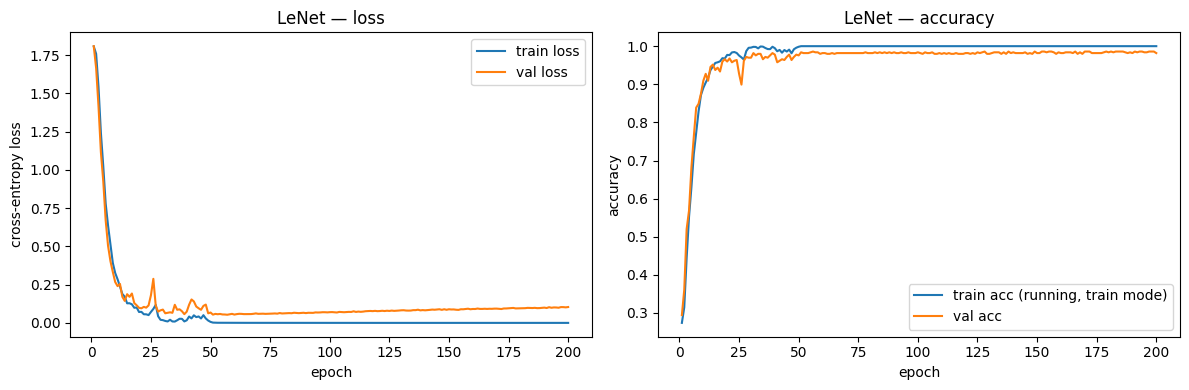

In [17]:
for name, r in RESULTS.items():
    h = r["history"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.epoch, h.train_loss, label="train loss"); ax[0].plot(h.epoch, h.val_loss, label="val loss")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title(f"{name} — loss"); ax[0].legend()
    ax[1].plot(h.epoch, h.train_acc, label="train acc (running, train mode)"); ax[1].plot(h.epoch, h.val_acc, label="val acc")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title(f"{name} — accuracy"); ax[1].legend()
    plt.tight_layout(); plt.savefig(r["dir"] / "training_curves.png", dpi=200); plt.show()

# CELL 19 — Load checkpoints
Loads **last** weights (repo protocol) and **best-val** weights (clean protocol) for each model.

In [18]:
def load_weights(name, which):
    m = MODEL_FACTORY[name]().to(DEVICE)
    ck = torch.load(RESULTS[name]["dir"] / f"{which}_model.pth", map_location=DEVICE)
    m.load_state_dict(ck["model"]); m.eval()
    return m, ck["epoch"]

EVAL = {}
for name in RESULTS:
    m_last, ep_last = load_weights(name, "last")
    m_best, ep_best = load_weights(name, "best")
    EVAL[name] = {"last": eval_all(m_last), "best": eval_all(m_best), "ep_last": ep_last, "ep_best": ep_best}
    print(f"{name}: last epoch = {ep_last} | best-val epoch = {ep_best}")
    del m_last, m_best

LeNet: last epoch = 200 | best-val epoch = 56


# CELL 20 — Test evaluation and classification metrics
Paper reports **accuracy only** (plus Flops/Params). Precision/recall/F1 are **[New]**; macro and weighted averages are both given.

In [19]:
def metric_row(preds, labels):
    p, r, f, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    return dict(acc=accuracy_score(labels, preds), prec_macro=p, rec_macro=r, f1_macro=f,
                prec_w=pw, rec_w=rw, f1_w=fw, n=len(labels))

METRICS = {}
for name, e in EVAL.items():
    l996, p996, y996 = e["last"]["repo996"]
    lt, pt, yt = e["best"]["test"]
    best_epoch_oracle = RESULTS[name]["history"].repo996_acc.max()
    METRICS[name] = {
        "P1_repo_final_epoch_996": metric_row(p996, y996),
        "P2_clean_bestval_test500": metric_row(pt, yt),
        "P1_repo_batchmean_acc": repo_batch_mean_acc(p996, y996, CONFIG["test_batch_size"]),
        "P3_oracle_best_epoch_996 (INVALID: picks epoch on test)": float(best_epoch_oracle),
    }
    print(f"\n=== {name} ===")
    print(pd.DataFrame({k: v for k, v in METRICS[name].items() if isinstance(v, dict)}).T.round(4).to_string())
    print("repo-style batch-mean accuracy (final epoch, 996):", round(METRICS[name]["P1_repo_batchmean_acc"], 4))
    print("oracle best-epoch accuracy on 996 (informational only):", round(float(best_epoch_oracle), 4))
    print("\nPer-class report — clean protocol (best-val checkpoint, test-only 500):")
    print(classification_report(yt, pt, labels=list(range(7)), target_names=CLASS_NAMES, digits=4, zero_division=0))


=== LeNet ===
                             acc  prec_macro  rec_macro  f1_macro  prec_w   rec_w    f1_w      n
P1_repo_final_epoch_996   0.9759      0.9639     0.9674    0.9654  0.9763  0.9759  0.9760  996.0
P2_clean_bestval_test500  0.9640      0.9496     0.9527    0.9503  0.9649  0.9640  0.9639  500.0
repo-style batch-mean accuracy (final epoch, 996): 0.9757
oracle best-epoch accuracy on 996 (informational only): 0.9769

Per-class report — clean protocol (best-val checkpoint, test-only 500):
              precision    recall  f1-score   support

    lie down     0.9836    0.9091    0.9449        66
        fall     0.9565    0.9778    0.9670        45
        walk     0.9730    0.9796    0.9763       147
      pickup     0.9434    1.0000    0.9709        50
         run     0.9917    0.9917    0.9917       121
    sit down     0.9459    0.8750    0.9091        40
    stand up     0.8529    0.9355    0.8923        31

    accuracy                         0.9640       500
   macro avg

# CELL 21 — Confusion matrices
Counts and row-normalised percentages. Class names follow the README order; the index-to-name mapping is an **assumption** (not stated in the repo code).

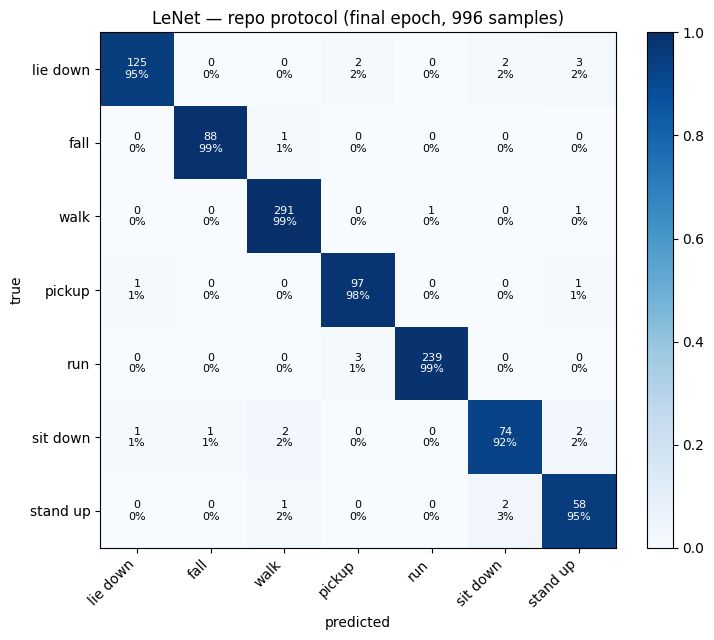

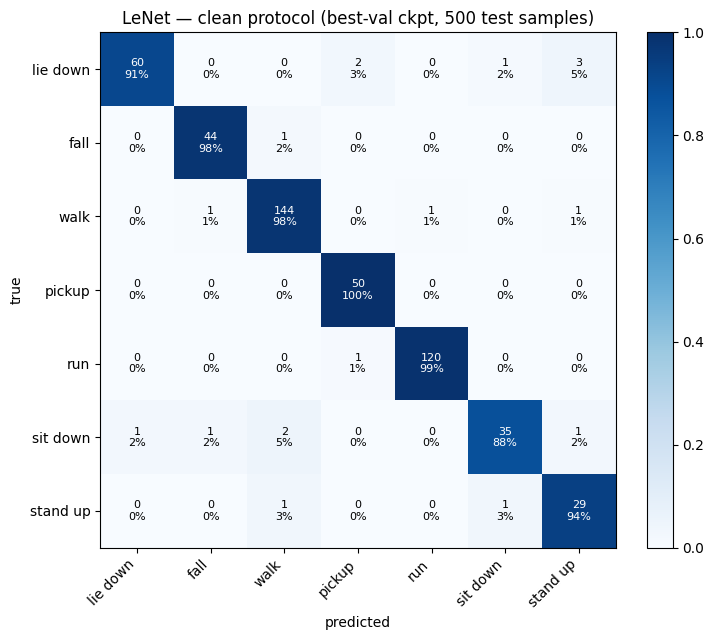

In [20]:
def plot_cm(preds, labels, title, path):
    cm = confusion_matrix(labels, preds, labels=list(range(7)))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(7)); ax.set_yticks(range(7))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    for i in range(7):
        for j in range(7):
            ax.text(j, i, f"{cm[i,j]}\n{100*cmn[i,j]:.0f}%", ha="center", va="center",
                    color="white" if cmn[i, j] > 0.5 else "black", fontsize=8)
    fig.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(path, dpi=200); plt.show()

for name, e in EVAL.items():
    _, p996, y996 = e["last"]["repo996"]
    _, pt, yt = e["best"]["test"]
    plot_cm(p996, y996, f"{name} — repo protocol (final epoch, 996 samples)", RESULTS[name]["dir"] / "cm_repo_protocol.png")
    plot_cm(pt, yt, f"{name} — clean protocol (best-val ckpt, 500 test samples)", RESULTS[name]["dir"] / "cm_clean_protocol.png")

# CELL 22 — Paper vs. reproduction
Paper Table III reports accuracy only; it does **not** say whether this is the final-epoch or best-epoch test accuracy (Fig. 5's axis is labelled "Best Test Accuracy") — *the source does not specify this*. Both readings are therefore shown, with the oracle one flagged invalid.

In [21]:
rows = []
for name in RESULTS:
    paper = PAPER_UT_HAR[name]["acc"]
    p1 = 100 * METRICS[name]["P1_repo_final_epoch_996"]["acc"]
    p2 = 100 * METRICS[name]["P2_clean_bestval_test500"]["acc"]
    p3 = 100 * METRICS[name]["P3_oracle_best_epoch_996 (INVALID: picks epoch on test)"]
    rows.append({"Model": name, "Paper acc %": paper,
                 "Ours P1 repo (final ep, 996) %": round(p1, 2), "Diff P1 (pp)": round(p1 - paper, 2),
                 "Ours P2 clean (best-val, 500) %": round(p2, 2), "Diff P2 (pp)": round(p2 - paper, 2),
                 "Oracle best-ep 996 % (invalid)": round(p3, 2),
                 "Params M (ours / paper)": f"{PARAM_STATUS[name][0]:.3f} / {PARAM_STATUS[name][1]:.3f}"})
COMPARISON = pd.DataFrame(rows).set_index("Model")
if DEBUG_MODE:
    print("*** DEBUG RUN (2 epochs): numbers below are NOT the paper configuration ***")
display(COMPARISON)
print("Paper-reported precision / recall / F1: not reported in the paper. Ours are in Cell 20 [New].")
print("Not an exact reproduction: single seed, test-set composition P1 = paper's 996, P2 uses a different 500-sample subset, "
      "environment/library versions differ from the authors'. P1 is the protocol comparable to the paper.")

,Paper acc %,"Ours P1 repo (final ep, 996) %",Diff P1 (pp),"Ours P2 clean (best-val, 500) %",Diff P2 (pp),Oracle best-ep 996 % (invalid),Params M (ours / paper)
Model,,,,,,,
LeNet,97.61,97.59,-0.02,96.4,-1.21,97.69,0.296 / 0.296


Paper-reported precision / recall / F1: not reported in the paper. Ours are in Cell 20 [New].
Not an exact reproduction: single seed, test-set composition P1 = paper's 996, P2 uses a different 500-sample subset, environment/library versions differ from the authors'. P1 is the protocol comparable to the paper.


# CELL 23 — Reproduction gap analysis

In [22]:
first = CONFIG["models"][0]
ep_used = {m: epochs_for(m) for m in RESULTS}
gap = pd.DataFrame([
    ["Dataset", "UT-HAR, 7 classes, (3,30,250), 3977 / 996",
     "UT_HAR csv(npy) -> (N,1,250,90)",
     f"{n_classes} classes, train {n_train}, test(val+test) {n_repo_test}",
     "MATCH" if all(ok) else "MISMATCH"],
    ["Preprocessing", "'normalize the data' (method unspecified)", "per-file min-max (own min/max per split)",
     CONFIG["norm_mode"], "MATCH" if CONFIG["norm_mode"] == "repo_per_file" else "ADAPTED (train-stats)"],
    ["Split", "8:2 stratified (all datasets)", "pre-split files; test = cat(val, test); no stratification code",
     "same files; val(496) used for checkpoint choice, test-only(500) for clean protocol", "ADAPTED (additional protocol P2)"],
    ["Model", "Appendix (not in provided PDF)", "UT_HAR_model.py", "verbatim copy; params vs Table III: " +
     ", ".join(f"{m}:{PARAM_STATUS[m][2]}" for m in PARAM_STATUS), "MATCH (repo)"],
    ["Loss", "not specified", "CrossEntropyLoss", "CrossEntropyLoss", "MATCH (repo)"],
    ["Optimizer", "Adam, betas (0.9, 0.999)", "Adam(lr=1e-3), default betas", f"Adam {CONFIG['betas']}", "MATCH"],
    ["LR", "1e-3, no schedule mentioned", "1e-3, no scheduler", f"{CONFIG['lr']}, no scheduler", "MATCH"],
    ["Epochs", "200 (RNN: 2x)", "200 (RNN: 3000 in util.py)", ", ".join(f"{m}:{e}" for m, e in ep_used.items()),
     "MATCH" if (all(e == 200 for m, e in ep_used.items() if m != "RNN") and not DEBUG_MODE) else "DEBUG/DIFFERS"],
    ["Batch size", "not specified", "train 64 (drop_last), test 256", f"{CONFIG['train_batch_size']} / {CONFIG['test_batch_size']}", "MATCH (repo)"],
    ["Seed", "not specified", "none set", f"{CONFIG['seed']}", "NEW"],
    ["Evaluation", "accuracy (final vs best epoch unspecified)", "final epoch, mean of per-batch accuracy on 996",
     "P1 = repo protocol; P2 = best-val ckpt on 500; P3 oracle (invalid)", "MATCH (P1) + extra"],
], columns=["Component", "Paper", "Repository", "My notebook", "Match?"])
pd.set_option("display.max_colwidth", 90); display(gap)

print("Known repo/paper discrepancies to cite when explaining differences:")
print(" 1. RNN epochs: paper 400 (2x200) vs repo util.py 3000.")
print(" 2. Paper says 8:2 stratified split; UT-HAR code uses the pre-split files (no stratification).")
print(" 3. Paper Table II size (3,30,250) vs repo tensor (1,250,90).")
print(" 4. Repo min-max normalises each split with its own min/max (train/test statistics differ).")
print(" 5. Repo test accuracy is a mean of per-batch accuracies; model is the FINAL epoch (no checkpoint selection).")
print(" 6. Overlapping sliding windows (paper Sec. V-A) -> optimistic accuracy; see overlap diagnostic in Cell 8.")
print(" 7. CNN+GRU: Softmax inside the model + CrossEntropyLoss (double softmax); ViT scaling after softmax.")

,Component,Paper,Repository,My notebook,Match?
0,Dataset,"UT-HAR, 7 classes, (3,30,250), 3977 / 996","UT_HAR csv(npy) -> (N,1,250,90)","7 classes, train 3977, test(val+test) 996",MATCH
1,Preprocessing,'normalize the data' (method unspecified),per-file min-max (own min/max per split),repo_per_file,MATCH
2,Split,8:2 stratified (all datasets),"pre-split files; test = cat(val, test); no stratification code","same files; val(496) used for checkpoint choice, test-only(500) for clean protocol",ADAPTED (additional protocol P2)
3,Model,Appendix (not in provided PDF),UT_HAR_model.py,verbatim copy; params vs Table III: LeNet:MATCH,MATCH (repo)
4,Loss,not specified,CrossEntropyLoss,CrossEntropyLoss,MATCH (repo)
5,Optimizer,"Adam, betas (0.9, 0.999)","Adam(lr=1e-3), default betas","Adam (0.9, 0.999)",MATCH
6,LR,"1e-3, no schedule mentioned","1e-3, no scheduler","0.001, no scheduler",MATCH
7,Epochs,200 (RNN: 2x),200 (RNN: 3000 in util.py),LeNet:200,MATCH
8,Batch size,not specified,"train 64 (drop_last), test 256",64 / 256,MATCH (repo)
9,Seed,not specified,none set,42,NEW


Known repo/paper discrepancies to cite when explaining differences:
 1. RNN epochs: paper 400 (2x200) vs repo util.py 3000.
 2. Paper says 8:2 stratified split; UT-HAR code uses the pre-split files (no stratification).
 3. Paper Table II size (3,30,250) vs repo tensor (1,250,90).
 4. Repo min-max normalises each split with its own min/max (train/test statistics differ).
 5. Repo test accuracy is a mean of per-batch accuracies; model is the FINAL epoch (no checkpoint selection).
 6. Overlapping sliding windows (paper Sec. V-A) -> optimistic accuracy; see overlap diagnostic in Cell 8.
 7. CNN+GRU: Softmax inside the model + CrossEntropyLoss (double softmax); ViT scaling after softmax.


# CELL 24 — Save results
Writes tables, metrics, configuration and library versions so the run can be audited.

In [23]:
COMPARISON.to_csv(OUT_DIR / "paper_vs_reproduction.csv")
gap.to_csv(OUT_DIR / "reproduction_gap_analysis.csv", index=False)
with open(OUT_DIR / "metrics.json", "w") as f:
    json.dump(METRICS, f, indent=2)

run_info = {
    "debug_mode": DEBUG_MODE,
    "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()},
    "epochs_used": {m: epochs_for(m) for m in RESULTS},
    "dataset_files": PATHS,
    "versions": {"python": platform.python_version(), "torch": torch.__version__, "numpy": np.__version__,
                 "sklearn": sklearn.__version__, "pandas": pd.__version__,
                 "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
                 "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None},
    "train_time_min": {m: round(r["train_time_s"] / 60, 1) for m, r in RESULTS.items()},
    "best_val_epoch": {m: r["best"]["epoch"] for m, r in RESULTS.items()},
}
with open(OUT_DIR / "run_info.json", "w") as f:
    json.dump(run_info, f, indent=2)

print(json.dumps(run_info, indent=2))
print("\nFiles in", OUT_DIR)
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {str(p.relative_to(OUT_DIR)):55s} {p.stat().st_size/1e6:8.2f} MB")

{
  "debug_mode": false,
  "config": {
    "dataset": "UT_HAR_data",
    "models": [
      "LeNet"
    ],
    "seed": 42,
    "train_batch_size": 64,
    "test_batch_size": 256,
    "lr": 0.001,
    "betas": [
      0.9,
      0.999
    ],
    "epochs": 200,
    "rnn_epoch_source": "paper",
    "norm_mode": "repo_per_file",
    "num_workers": 0,
    "ckpt_every": 10,
    "data_dir_override": null
  },
  "epochs_used": {
    "LeNet": 200
  },
  "dataset_files": {
    "X_train": "/kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/data/X_train.csv",
    "X_val": "/kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/data/X_val.csv",
    "X_test": "/kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/data/X_test.csv",
    "y_train": "/kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/label/y_train.csv",
    "y_val": "/kaggle/input/datasets/pawankapakayala/wifi-csi-kssp/UT_HAR/UT_HAR/label/y_val.csv",
    "y_test": "/kaggle/input/da